# 2. Pré-processamento das imagens
A equipe deverá selecionar e avaliar operações de pré-processamento adequadas ao problema, justificando suas escolhas.

Poderão ser consideradas operações como redimensionamento, conversão de espaço de cores, redução de ruído, ajuste de contraste e normalização.

Não é necessário aplicar todas essas operações. Cada técnica utilizada deverá ter uma finalidade relacionada às características do dataset.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import cv2
import random
import matplotlib.pyplot as plt

df_treino = pd.read_csv("treino_reduzido.csv")
df_teste = pd.read_csv("teste_reduzido.csv")

print("Treino:", df_treino.shape, "| Teste:", df_teste.shape)
display(df_treino.head())

# Teste de sanidade: o caminho salvo no CSV existe na sua máquina?
primeiro = Path(df_treino.loc[0, "caminho"])
print(primeiro, "->", primeiro.exists())

Matplotlib is building the font cache; this may take a moment.


Treino: (37528, 2) | Teste: (12528, 2)


,classe,caminho
0,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_85_10...
1,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_17_10...
2,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_10_10...
3,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_302_1...
4,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_117_1...


fruits-360-100x100\Training\Almonds 1\r0_85_100.jpg -> True


In [11]:
def carregar_rgb(caminho):
    img = cv2.imread(str(caminho))
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

amostra = df_treino.sample(500, random_state=42)

formatos, tipos = set(), set()
brilho_borda = []   # média dos pixels da borda da imagem (deve ser fundo)

for caminho in amostra["caminho"]:
    img = carregar_rgb(caminho)
    formatos.add(img.shape)
    tipos.add(str(img.dtype))
    borda = np.concatenate([img[0], img[-1], img[:, 0], img[:, -1]])
    brilho_borda.append(borda.mean())

print("Formatos encontrados:", formatos)
print("Tipos de dado:", tipos)
print(f"Brilho médio da borda: {np.mean(brilho_borda):.1f} "
      f"(mín {np.min(brilho_borda):.1f}, máx {np.max(brilho_borda):.1f})")

Formatos encontrados: {(100, 100, 3)}
Tipos de dado: {'uint8'}
Brilho médio da borda: 245.9 (mín 212.5, máx 254.8)


### Conclusões do tópico 2.1
Na amostra de 500 imagens do treino, todas possuem formato (100, 100, 3) e tipo uint8.
Portanto, **o redimensionamento não é necessário**. O brilho médio da borda foi 245,9
(mín. 212,5; máx. 254,8), indicando que o fundo não é branco puro, provavelmente
por compressão JPG, e que em algumas imagens o objeto toca a borda.

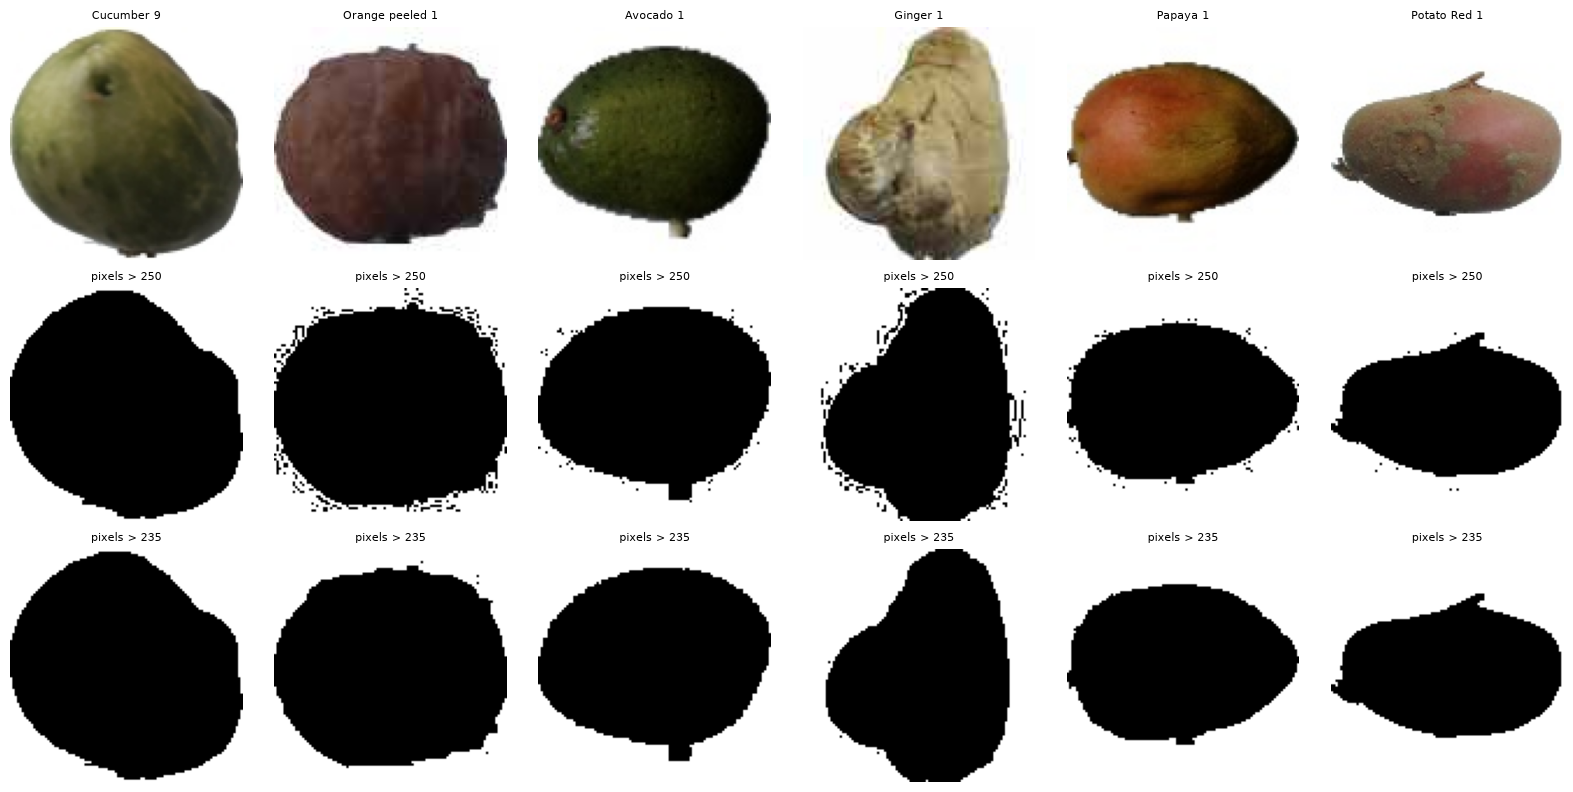

In [12]:
# Visualizando como é o fundo "branco" das imagens
amostra_vis = df_treino.sample(6, random_state=1)

fig, axes = plt.subplots(3, 6, figsize=(16, 8))

for i, (classe, caminho) in enumerate(zip(amostra_vis["classe"], amostra_vis["caminho"])):
    img = carregar_rgb(caminho)
    cinza = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    axes[0, i].imshow(img)
    axes[0, i].set_title(classe, fontsize=8)

    axes[1, i].imshow(cinza > 250, cmap="gray")
    axes[1, i].set_title("pixels > 250", fontsize=8)

    axes[2, i].imshow(cinza > 235, cmap="gray")
    axes[2, i].set_title("pixels > 235", fontsize=8)

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show() 

### Conclusões do tópico 2.2
Com limiar > 250 o contorno apresenta ruído (pontos isolados); com > 235 fica mais
contínuo. A sensibilidade ao limiar escolhido mostra que um valor fixo é frágil,
o que justifica o uso de um método automático (Otsu) na Etapa 3.

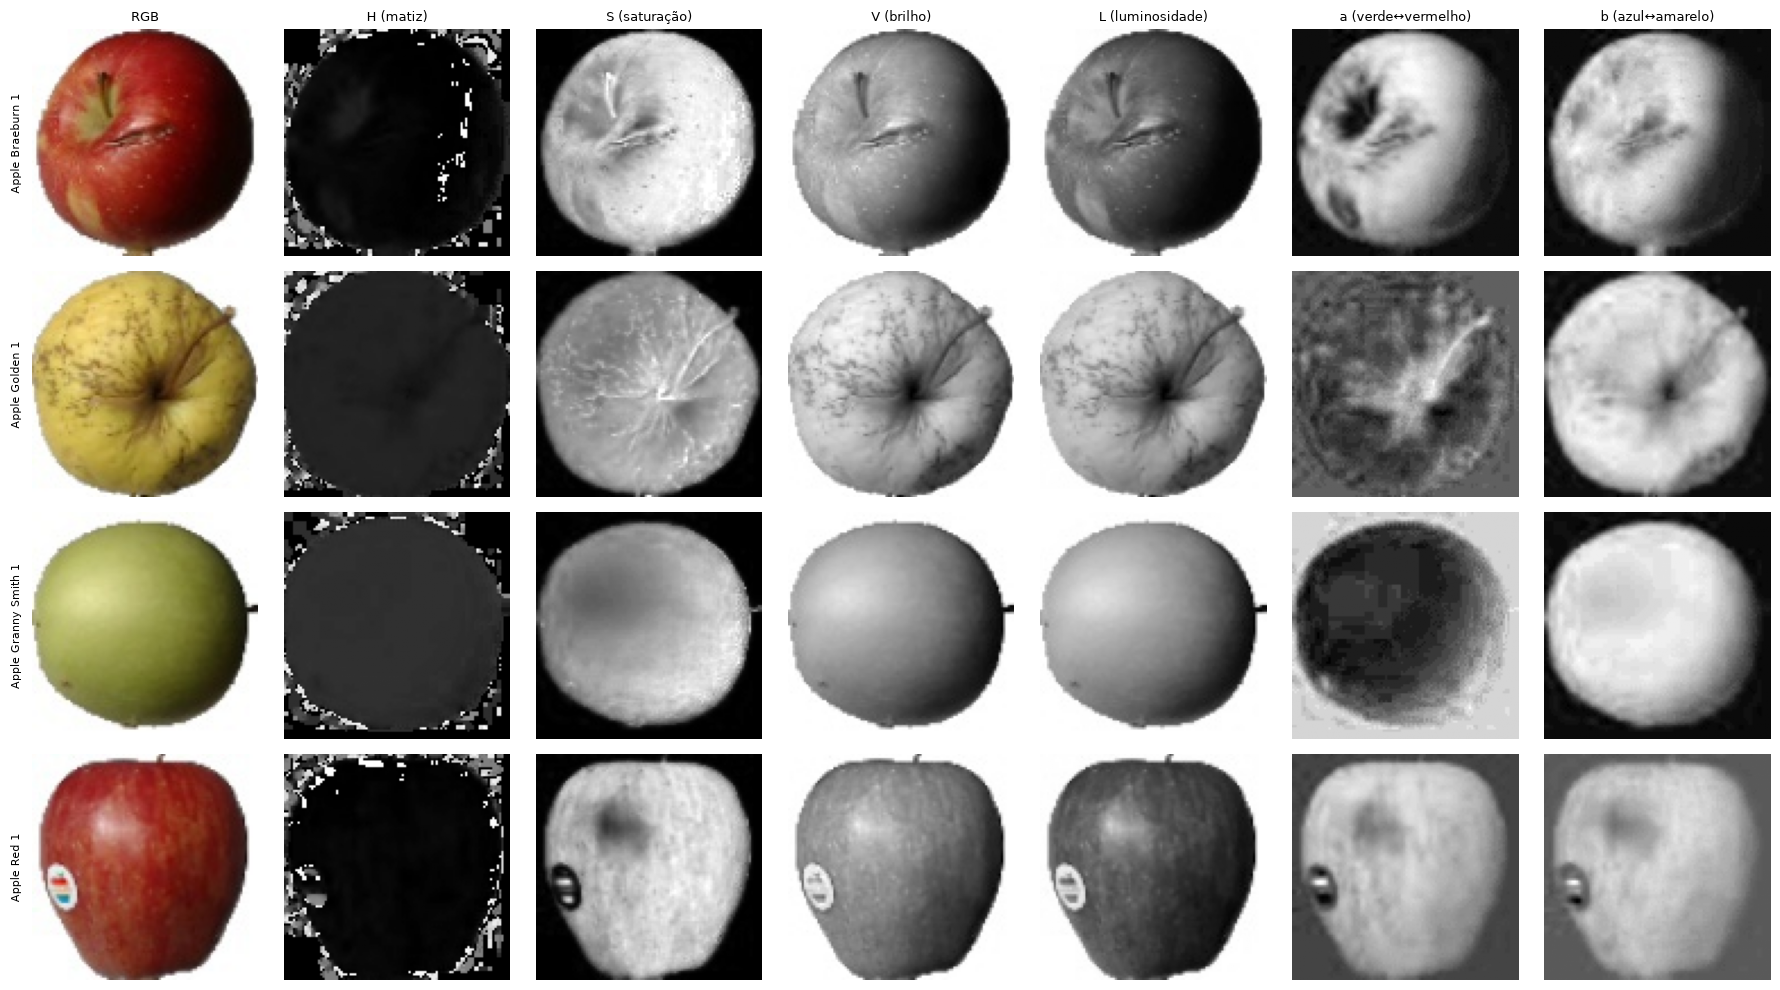

In [ ]:
classes_cmp = ["Apple Braeburn 1", "Apple Golden 1", "Apple Granny Smith 1", "Apple Red 1"]

fig, axes = plt.subplots(len(classes_cmp), 7, figsize=(18, 10))
titulos = ["RGB", "H (matiz)", "S (saturação)", "V (brilho)", "L (luminosidade)", "a (verde↔vermelho)", "b (azul↔amarelo)"]

for i, classe in enumerate(classes_cmp):
    caminho = df_treino[df_treino["classe"] == classe].sample(1, random_state=3)["caminho"].iloc[0]
    rgb = carregar_rgb(caminho)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)   # H: 0-179, S e V: 0-255
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)   # L, a, b: 0-255 em uint8

    canais = [rgb, hsv[..., 0], hsv[..., 1], hsv[..., 2], lab[..., 0], lab[..., 1], lab[..., 2]]
    for j, canal in enumerate(canais):
        axes[i, j].imshow(canal, cmap=None if j == 0 else "gray")
        axes[i, j].axis("off")
        if i == 0:
            axes[i, j].set_title(titulos[j], fontsize=9)
    axes[i, 0].set_ylabel(classe)
    axes[i, 0].text(-5, 50, classe, rotation=90, va="center", ha="right", fontsize=8)

plt.tight_layout()
plt.show()

### Conclusões do tópico 2.3 — Espaços de cor

Para investigar qual espaço de cor representa melhor as diferenças entre variedades
parecidas, foram comparadas quatro variedades de maçã (Braeburn, Golden, Granny Smith
e Red) nos espaços RGB, HSV e Lab, com cada canal exibido separadamente.

**Canais de cor (H, a, b).** Os canais *a* e *b* do Lab separaram bem as variedades
por tonalidade: as maçãs vermelhas ficaram claras no canal *a* e a Granny Smith
(verde) ficou escura; as maçãs amarelas e verdes ficaram claras no canal *b*. O canal
H do HSV também diferenciou as variedades (vermelho próximo de 0, amarelo e verde
em valores progressivamente maiores), e nesses canais o sombreamento do objeto
influenciou pouco.

**Canais de iluminação (V e L).** Os canais V e L mostraram principalmente o
sombreamento do objeto: na Braeburn, o lado direito aparece escuro e na Granny Smith
há um gradiente suave de claro para escuro. Como a mesma fruta pode aparecer com
iluminações diferentes, esses canais carregam variação dentro da classe e não
identificam a variedade.

**Canal S e o fundo.** No canal S o fundo aparece escuro (saturação próxima de zero)
e a fruta clara, o que o torna um bom candidato para separar objeto e fundo na
Etapa 3. Por outro lado, no canal H o fundo aparece ruidoso, pois o matiz é instável
quando a saturação é baixa.

**Limitações observadas.**
- O canal H é circular: o vermelho fica próximo de 0 e de 179, e alguns pixels de
  maçãs vermelhas aparecem muito claros (valor alto) no canal H, mesmo sendo
  vermelhos. Isso deve ser considerado ao extrair histogramas de matiz.
- Pixels do fundo, de reflexos e de regiões muito claras distorcem H. Convém calcular
  descritores de cor apenas sobre os pixels do objeto (máscara da Etapa 3).
- Braeburn e Red 1 ficaram muito parecidas nos canais de cor; a diferença entre elas
  está mais no padrão da superfície (listras) do que na cor média. Isso reforça que a
  cor, isoladamente, não é suficiente e que descritores de textura serão necessários.
- A Red 1 possui uma etiqueta adesiva, que aparece claramente nos canais S e V e
  pode introduzir ruído nos descritores de cor.
- A análise foi qualitativa e feita com apenas quatro imagens de uma mesma fruta.

**Decisão.** O RGB mistura cor e iluminação nos três canais, então não será usado
diretamente nos descritores de cor. Serão utilizados o HSV (canais H e S) e o Lab
(canais a e b) como representações de cor, e os canais V e L para a análise de brilho
e textura. A conversão será feita com cv2.cvtColor, e essas escolhas serão revisadas
na Etapa 4 com o desempenho dos classificadores.

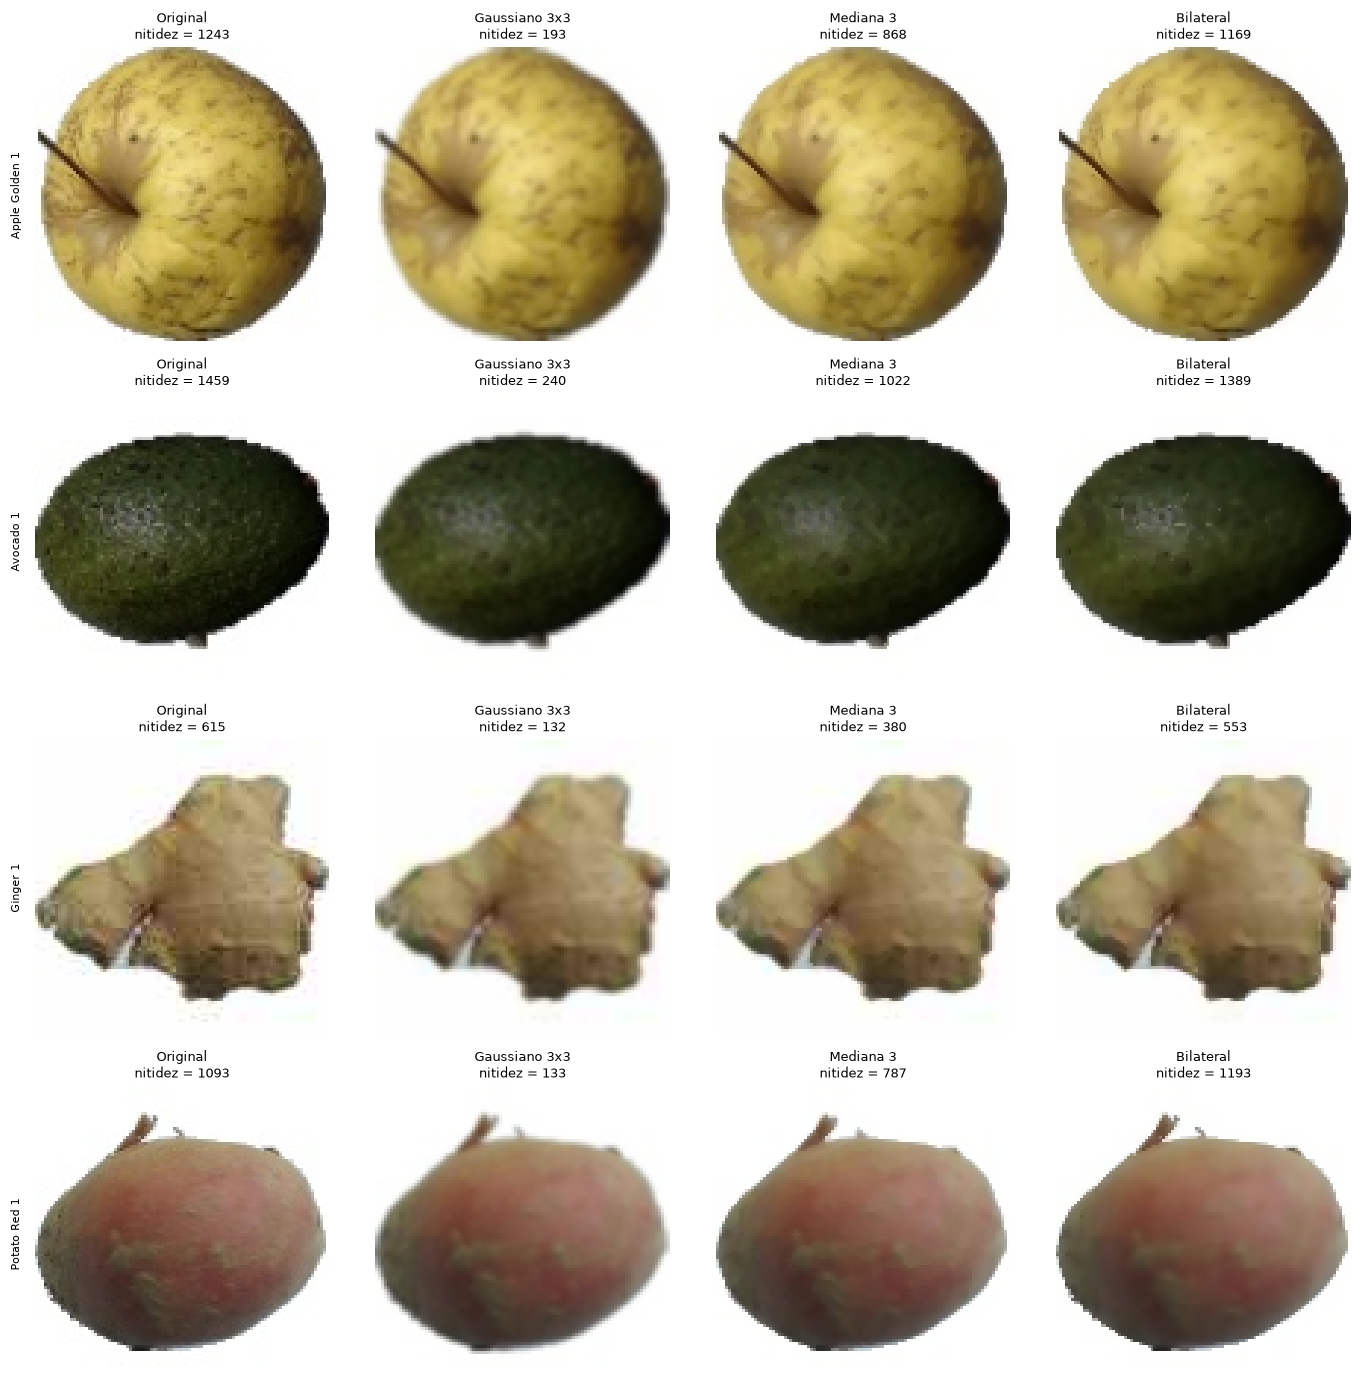

Nitidez preservada após cada filtro (média das 300 imagens):
  Gaussiano 3x3   -> 17.5% da nitidez original (mediana 16.6%)
  Mediana 3       -> 79.0% da nitidez original (mediana 81.9%)
  Bilateral       -> 109.5% da nitidez original (mediana 110.5%)


In [ ]:
# ============================================================
# 2.4 - Redução de ruído: comparação de filtros
# Objetivo: verificar se algum filtro compensa. O risco é borrar
# a textura da casca, que será usada na Etapa 4 (LBP, GLCM).
# Filtros testados: Gaussiano, Mediana e Bilateral.
# Métrica: variância do Laplaciano (quanto MAIOR, mais nítida a
# imagem; se o filtro derruba muito esse valor, ele está borrando).
# ============================================================

# --- Dicionário de filtros (cada um recebe uma imagem RGB e devolve outra) ---
filtros = {
    "Original":      lambda im: im,
    "Gaussiano 3x3": lambda im: cv2.GaussianBlur(im, (3, 3), 0),   # média ponderada da vizinhança
    "Mediana 3":     lambda im: cv2.medianBlur(im, 3),             # mediana da vizinhança (bom contra pontos isolados)
    "Bilateral":     lambda im: cv2.bilateralFilter(im, d=5, sigmaColor=50, sigmaSpace=50),  # suaviza preservando bordas
}

def nitidez(img_rgb):
    """Variância do Laplaciano da imagem em tons de cinza.
    O Laplaciano responde a bordas e detalhes finos; sua variância
    funciona como medida simples de nitidez/textura."""
    cinza = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cv2.Laplacian(cinza, cv2.CV_64F).var()

# ------------------------------------------------------------
# Parte A - Comparação visual em frutas com textura marcante
# ------------------------------------------------------------
classes_filtro = ["Apple Golden 1", "Avocado 1", "Ginger 1", "Potato Red 1"]

fig, axes = plt.subplots(len(classes_filtro), len(filtros), figsize=(14, 14))

for i, classe in enumerate(classes_filtro):
    caminho = df_treino[df_treino["classe"] == classe].sample(1, random_state=5)["caminho"].iloc[0]
    rgb = carregar_rgb(caminho)

    for j, (nome, func) in enumerate(filtros.items()):
        resultado = func(rgb)
        # interpolation="nearest" mostra os pixels reais, sem suavização do matplotlib
        axes[i, j].imshow(resultado, interpolation="nearest")
        axes[i, j].set_title(f"{nome}\nnitidez = {nitidez(resultado):.0f}", fontsize=9)
        axes[i, j].axis("off")
    axes[i, 0].text(-5, 50, classe, rotation=90, va="center", ha="right", fontsize=8)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Parte B - Medição em 300 imagens do treino (todas as classes)
# Para cada filtro, calculamos quanto da nitidez original sobrou:
# razão = nitidez após o filtro / nitidez original (1.0 = nada mudou)
# ------------------------------------------------------------
amostra_filtros = df_treino.sample(300, random_state=7)
razoes = {nome: [] for nome in filtros if nome != "Original"}

for caminho in amostra_filtros["caminho"]:
    rgb = carregar_rgb(caminho)
    base = nitidez(rgb)
    if base == 0:      # evita divisão por zero (imagem totalmente uniforme)
        continue
    for nome, func in filtros.items():
        if nome == "Original":
            continue
        razoes[nome].append(nitidez(func(rgb)) / base)

print("Nitidez preservada após cada filtro (média das 300 imagens):")
for nome, valores in razoes.items():
    print(f"  {nome:15s} -> {np.mean(valores)*100:.1f}% da nitidez original "
          f"(mediana {np.median(valores)*100:.1f}%)")

### Conclusões do tópico 2.4 — Redução de ruído

Foram comparados três filtros (Gaussiano 3x3, Mediana 3 e Bilateral) em frutas de
textura marcante (Apple Golden, Avocado, Ginger e Potato Red) e em uma amostra de
300 imagens do treino, usando a variância do Laplaciano como medida de nitidez.

O filtro Gaussiano preservou em média apenas 17,5% da nitidez original e borrou
visivelmente a textura da casca, que será usada pelos descritores da Etapa 4
(LBP e GLCM). A Mediana preservou 79%, com perda moderada de detalhes e aspecto
mais "pintado". O Bilateral resultou em 109,5% e visualmente ficou muito próximo
do original; um valor acima de 100% não indica melhora da imagem e sugere que a
métrica é sensível a efeitos do filtro que não são ganho de qualidade.

Observou-se também que o que poderia parecer ruído (pontos na casca do abacate, rugosidade
do gengibre) é textura própria dos objetos, e que as imagens não apresentam ruído
de sensor evidente. O principal artefato é a compressão JPG no contorno.

**Limitação:** a variância do Laplaciano não distingue ruído de textura, pois ambos
são detalhes finos. A métrica indica o quanto o filtro altera a imagem, mas não se
a alteração é benéfica. A análise foi complementada pela inspeção visual.

**Decisão:** a redução de ruído não será aplicada como etapa padrão, pois o filtro
mais comum (Gaussiano) destrói textura relevante e os demais não mostraram ganho
claro. Eventuais artefatos de borda serão tratados na segmentação (Etapa 3), com
operações morfológicas. A mediana poderá ser avaliada de forma experimental na
Etapa 5 (com e sem filtro).

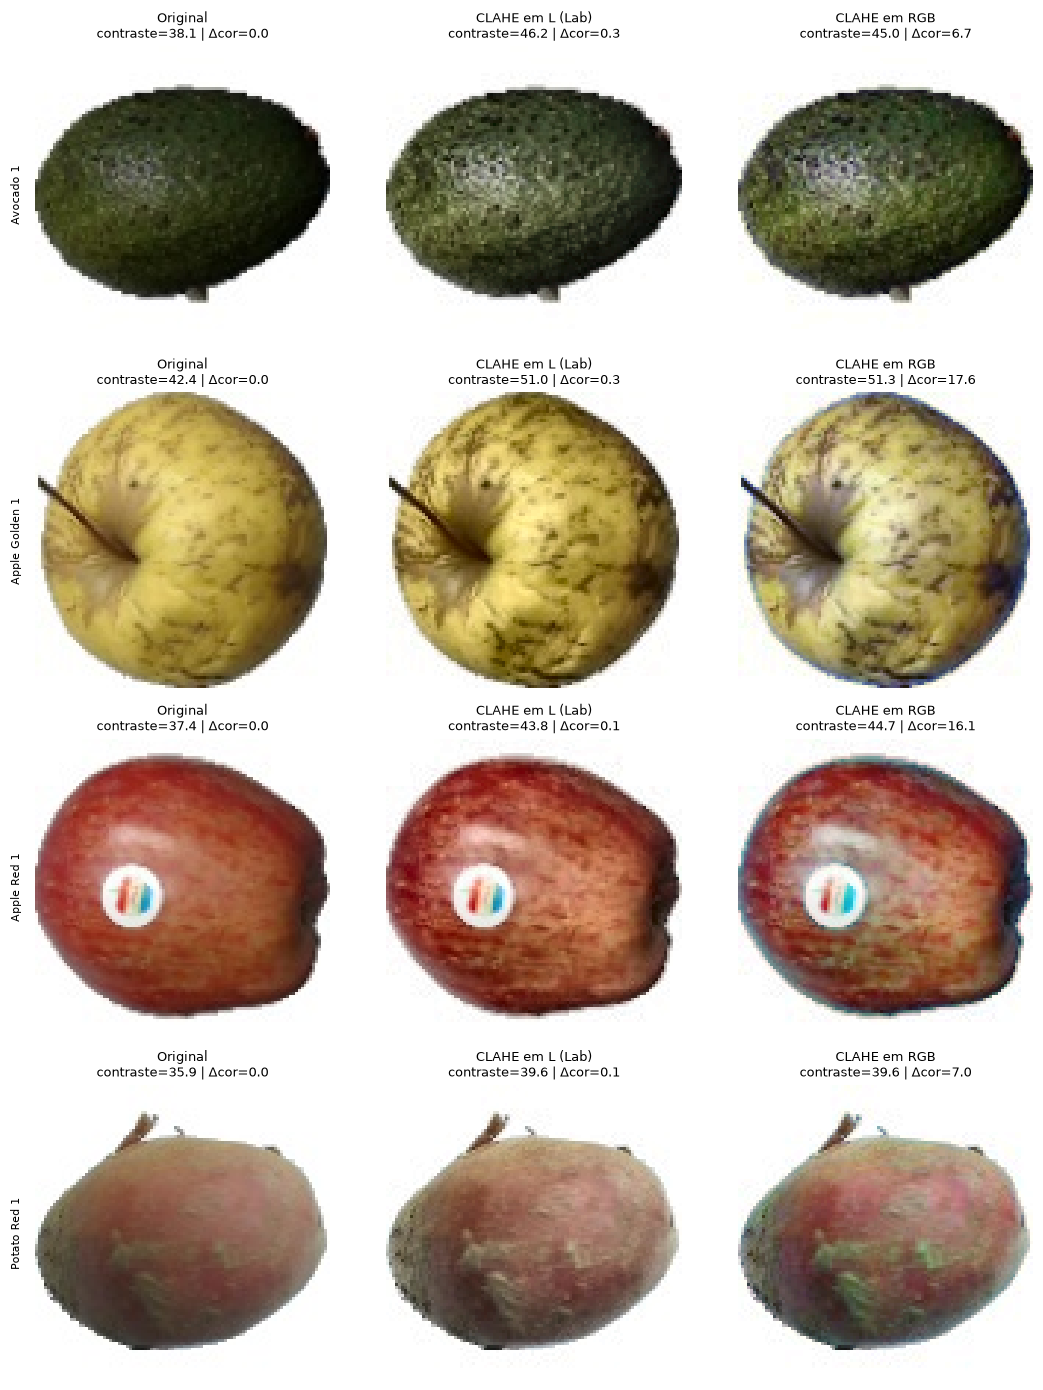

Média em 300 imagens (medido só dentro da fruta):
  Original           contraste = 38.7 | alteração da cor (Δcor) = 0.00
  CLAHE em L (Lab)   contraste = 44.8 | alteração da cor (Δcor) = 0.24
  CLAHE em RGB       contraste = 44.6 | alteração da cor (Δcor) = 9.29


In [ ]:
# ============================================================
# 2.5 - Ajuste de contraste: CLAHE
# Objetivo: avaliar se o CLAHE realça a textura sem alterar a cor.
# Versões comparadas:
#   (1) Original
#   (2) CLAHE só no canal L do Lab (preserva a cor, em teoria)
#   (3) CLAHE em cada canal RGB (versão "errada", só para comparação)
# ============================================================

def clahe_lab(img_rgb, clip=2.0, grade=(4, 4)):
    """Aplica CLAHE apenas na luminosidade (canal L do Lab).
    grade=(4,4): imagem dividida em 4x4 quadrados (as imagens são pequenas, 100x100)."""
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    L, a, b = cv2.split(lab)                      # separa os 3 canais
    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=grade)
    L2 = clahe.apply(L)                           # só o L é modificado
    return cv2.cvtColor(cv2.merge([L2, a, b]), cv2.COLOR_LAB2RGB)

def clahe_rgb(img_rgb, clip=2.0, grade=(4, 4)):
    """Versão errada: CLAHE em cada canal R, G e B separadamente."""
    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=grade)
    canais = [clahe.apply(img_rgb[..., k]) for k in range(3)]
    return np.stack(canais, axis=-1)

def mascara_objeto(img_rgb):
    """Máscara aproximada da fruta: pixels que NÃO são fundo claro.
    Usa o limiar 235, que na célula 3 deu o contorno mais limpo.
    Serve só para medir dentro da fruta (a segmentação de verdade é a Etapa 3)."""
    cinza = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cinza < 235

def metricas(orig, proc):
    """Retorna (contraste, desvio_de_cor) medidos só dentro da fruta.
    contraste: desvio padrão da luminosidade L (maior = mais contraste).
    desvio_de_cor: quanto os canais a e b mudaram em relação ao original
                   (0 = cor idêntica; quanto maior, mais a cor foi alterada)."""
    mask = mascara_objeto(orig)
    if mask.sum() == 0:
        return None
    lab_o = cv2.cvtColor(orig, cv2.COLOR_RGB2LAB).astype(float)
    lab_p = cv2.cvtColor(proc, cv2.COLOR_RGB2LAB).astype(float)
    contraste = lab_p[..., 0][mask].std()
    desvio_cor = (np.abs(lab_p[..., 1] - lab_o[..., 1])[mask]
                  + np.abs(lab_p[..., 2] - lab_o[..., 2])[mask]).mean()
    return contraste, desvio_cor

versoes = {
    "Original":        lambda im: im,
    "CLAHE em L (Lab)": clahe_lab,
    "CLAHE em RGB":    clahe_rgb,
}

# ------------------------------------------------------------
# Parte A - Comparação visual (inclui uma imagem escura: Avocado)
# ------------------------------------------------------------
classes_clahe = ["Avocado 1", "Apple Golden 1", "Apple Red 1", "Potato Red 1"]

fig, axes = plt.subplots(len(classes_clahe), len(versoes), figsize=(11, 14))

for i, classe in enumerate(classes_clahe):
    caminho = df_treino[df_treino["classe"] == classe].sample(1, random_state=5)["caminho"].iloc[0]
    rgb = carregar_rgb(caminho)

    for j, (nome, func) in enumerate(versoes.items()):
        resultado = func(rgb)
        m = metricas(rgb, resultado)
        axes[i, j].imshow(resultado, interpolation="nearest")
        axes[i, j].set_title(f"{nome}\ncontraste={m[0]:.1f} | Δcor={m[1]:.1f}", fontsize=9)
        axes[i, j].axis("off")
    axes[i, 0].text(-5, 50, classe, rotation=90, va="center", ha="right", fontsize=8)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Parte B - Medição em 300 imagens do treino
# ------------------------------------------------------------
amostra_clahe = df_treino.sample(300, random_state=7)
resultados = {nome: {"contraste": [], "cor": []} for nome in versoes}

for caminho in amostra_clahe["caminho"]:
    rgb = carregar_rgb(caminho)
    for nome, func in versoes.items():
        m = metricas(rgb, func(rgb))
        if m is not None:
            resultados[nome]["contraste"].append(m[0])
            resultados[nome]["cor"].append(m[1])

print("Média em 300 imagens (medido só dentro da fruta):")
for nome, r in resultados.items():
    print(f"  {nome:18s} contraste = {np.mean(r['contraste']):.1f} | "
          f"alteração da cor (Δcor) = {np.mean(r['cor']):.2f}")

### Conclusões do tópico 2.5 — Ajuste de contraste (CLAHE)

Foram comparadas três versões em 300 imagens do treino: original, CLAHE aplicado
apenas no canal L do espaço Lab e CLAHE aplicado separadamente em cada canal RGB.
As métricas foram calculadas apenas dentro da fruta (máscara aproximada por limiar),
usando o desvio padrão de L como medida de contraste e a variação dos canais a e b
em relação ao original como medida de alteração da cor.

O contraste médio passou de 38,7 (original) para 44,8 (CLAHE em L) e 44,6 (CLAHE em
RGB), ou seja, ambos aumentaram o contraste de forma semelhante. A diferença está na
cor: a alteração média foi de 0,24 no CLAHE em L e de 9,29 no CLAHE em RGB. Na
inspeção visual, o CLAHE em RGB gerou halos azulados nos contornos (Golden e Red 1) e
manchas esverdeadas na batata, enquanto o CLAHE em L realçou a textura (pontos do
abacate, manchas da Golden, listras da Red 1) preservando a cor.

**Limitações:**
- O aumento de contraste não garante melhora na classificação; isso só pode ser
  verificado nas etapas seguintes.
- O CLAHE pode amplificar também variações de iluminação e sombreamento, o que poderia
  aumentar a variação intraclasse (hipótese não testada).
- Os parâmetros (clipLimit = 2,0 e grade 4x4) foram escolhidos sem otimização.
- A máscara usada nas métricas é uma aproximação por limiar; a segmentação formal
  será feita na Etapa 3.
- O Δcor do CLAHE em L não é exatamente zero devido a arredondamentos nas conversões
  entre espaços de cor.

**Decisão:** o CLAHE em RGB está descartado por alterar a cor. O CLAHE em L fica como
etapa opcional: será avaliado na Etapa 5 comparando o desempenho dos classificadores
com e sem ele, e só será mantido no pipeline se trouxer ganho.

In [ ]:
# ============================================================
# 2.6 - Normalização dos valores de pixel
# Objetivo: converter os pixels de inteiros 0-255 (uint8) para
# decimais 0-1 (float32), escala adequada para algoritmos de ML.
# Verificamos também se a conversão não perde informação.
# ============================================================

def normalizar(img_uint8):
    """Converte uint8 (0-255) para float32 (0-1)."""
    return img_uint8.astype(np.float32) / 255.0

def desnormalizar(img_float):
    """Operação inversa: float32 (0-1) volta para uint8 (0-255)."""
    return np.round(img_float * 255.0).astype(np.uint8)

# --- Teste em 300 imagens do treino ---
amostra_norm = df_treino.sample(300, random_state=7)
minimos, maximos, dif_max = [], [], []

for caminho in amostra_norm["caminho"]:
    rgb = carregar_rgb(caminho)
    norm = normalizar(rgb)
    volta = desnormalizar(norm)

    minimos.append(norm.min())
    maximos.append(norm.max())
    # diferença máxima entre a imagem original e a que fez o "ida e volta"
    dif_max.append(np.abs(rgb.astype(int) - volta.astype(int)).max())

print("Tipo antes:", rgb.dtype, "| Tipo depois:", norm.dtype)
print(f"Menor valor encontrado: {np.min(minimos):.3f}")
print(f"Maior valor encontrado: {np.max(maximos):.3f}")
print(f"Maior diferença após normalizar e voltar: {np.max(dif_max)} (0 = sem perda)")

# --- Custo de memória: por que NÃO normalizar o dataset inteiro de uma vez ---
n_img = len(df_treino)
bytes_uint8 = n_img * 100 * 100 * 3
bytes_float32 = bytes_uint8 * 4
print(f"\nTreino inteiro em uint8:   {bytes_uint8 / 1e9:.1f} GB")
print(f"Treino inteiro em float32: {bytes_float32 / 1e9:.1f} GB")

Tipo antes: uint8 | Tipo depois: float32
Menor valor encontrado: 0.000
Maior valor encontrado: 1.000
Maior diferença após normalizar e voltar: 0 (0 = sem perda)

Treino inteiro em uint8:   1.1 GB
Treino inteiro em float32: 4.5 GB


In [ ]:
# ============================================================
# 2.7 - Função final do pré-processamento (entrega para a Etapa 4)
# Reúne as decisões da Etapa 2 em uma única função reutilizável.
# ============================================================

def preprocessar(img_rgb, usar_clahe=False):
    """Pré-processamento da Etapa 2.
    Entrada: imagem RGB uint8 (100x100x3).
    Saída:   imagem RGB uint8; o CLAHE é opcional.
    Decisões: sem redimensionamento (imagens já 100x100) e sem filtro de ruído
    (destrói textura). A normalização para float32 [0,1] é feita por
    quem usa a imagem, com normalizar(), para economizar memória."""
    if usar_clahe:
        return clahe_lab(img_rgb)   # definida na célula 6 (CLAHE só no canal L)
    return img_rgb

# --- Teste rápido da função ---
caminho_teste = df_treino.sample(1, random_state=11)["caminho"].iloc[0]
img = carregar_rgb(caminho_teste)
img_proc = preprocessar(img, usar_clahe=True)
img_final = normalizar(img_proc)
print("Formato:", img_final.shape, "| Tipo:", img_final.dtype,
      f"| Faixa: [{img_final.min():.2f}, {img_final.max():.2f}]")

Formato: (100, 100, 3) | Tipo: float32 | Faixa: [0.00, 1.00]


### Conclusões do tópico 2.6 — Normalização

Os valores de pixel foram convertidos de uint8 (0 a 255) para float32 (0 a 1)
dividindo por 255. Em 300 imagens do treino, os valores resultantes ficaram no
intervalo [0, 1] e a operação inversa recuperou exatamente as imagens originais
(diferença máxima de 0), confirmando que a conversão não perde informação.

Como o float32 ocupa quatro vezes mais memória que o uint8, a normalização será
aplicada imagem por imagem durante a extração de características, e não sobre o
dataset inteiro.

**Limitações e cuidados:**
- A normalização por 255 é uma mudança de escala, e não corrige diferenças de
  iluminação entre imagens.
- A padronização das características (por exemplo, com StandardScaler) é um passo
  diferente e pertence à Etapa 5. Ela deve ser ajustada apenas com o conjunto de
  treino, para evitar vazamento de dados.
- Convém converter os espaços de cor (HSV, Lab) a partir da imagem uint8, antes de
  normalizar. Em imagens float, o OpenCV usa escalas diferentes (por exemplo, H de 0
  a 360 no HSV), o que pode causar confusão.

**Decisão:** a normalização para [0, 1] será mantida como último passo do pré-processamento.

## Conclusão da Etapa 2 — Pré-processamento das imagens

As técnicas foram avaliadas com base nas características do Fruits-360: imagens
100x100 em JPEG, objeto centralizado, fundo claro com variações por compressão e
textura de casca relevante para distinguir variedades parecidas.

| Técnica | Decisão | Justificativa |
|---|---|---|
| Redimensionamento | Não aplicada | Todas as imagens da amostra já têm 100x100 pixels. |
| Espaço de cor | HSV (H e S) e Lab (a e b) para cor; V e L para brilho | Separam cor e iluminação; o RGB mistura os dois. O canal H exige cuidado (circular, instável sem cor). |
| Redução de ruído | Não aplicada | O Gaussiano reduziu a nitidez a 17,5% e a mediana a 79%; o que parece ruído é textura real da casca. |
| Contraste (CLAHE) | Opcional, só no canal L | Subiu o contraste de 38,7 para 44,8 com Δcor de 0,24; em RGB a cor mudou 9,29. Será validado na Etapa 5. |
| Normalização | Aplicada ([0, 1], float32) | Escala adequada para ML; sem perda de informação; feita imagem por imagem. |

Como o dataset já vem com o fundo isolado e sem ruído evidente, o pré-processamento
foi propositalmente enxuto: cada técnica só entra se houver ganho demonstrado. As
análises foram qualitativas e feitas em amostras do conjunto de treino; os parâmetros
não foram otimizados. A validação final de cada escolha depende do desempenho dos
classificadores nas etapas seguintes.